In [2]:
# Import necessary libraries
import pandas as pd
import glob
import numpy as np
import xarray as xr
from pathlib import Path
import matplotlib.pyplot as plt
import requests
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm
from scipy.spatial import KDTree
from scipy.stats import mode as sp_mode

In [3]:
# Define the name of your Excel file
file_name = 'FRESCA 2024_2025 data_Final_Share.xlsx'

try:
    # Read all sheets from the Excel file into a dictionary of DataFrames.
    # Setting sheet_name=None tells pandas to load all sheets.
    all_sheets_dict = pd.read_excel(file_name, sheet_name=None)

    # Combine all the DataFrames from the dictionary into a single DataFrame.
    # ignore_index=True creates a new, continuous index for the combined data.
    fresca_df = pd.concat(all_sheets_dict.values(), ignore_index=True)

    # Rename the column to remove spaces and parentheses
    fresca_df.rename(columns={'IFCB filename': 'ifcb_filename'}, inplace=True)
    fresca_df.rename(columns={'datetime (UTC)': 'datetime_utc'}, inplace=True)
    fresca_df.rename(columns={'K.brevis total adhoc (cells/L)': 'k_brevis_total'}, inplace=True)  
    fresca_df.rename(columns={'mL analyzed': 'sample_vol'}, inplace=True)  

    # Ensure the column is in the correct datetime format
    # errors='coerce' will turn any unreadable dates into NaT (Not a Time)
    fresca_df['datetime_utc'] = pd.to_datetime(fresca_df['datetime_utc'], errors='coerce')

    # Now, find the min and max dates on the cleaned column
    # .dropna() is added to handle any potential NaT values
    min_date = fresca_df['datetime_utc'].dropna().min()
    max_date = fresca_df['datetime_utc'].dropna().max()

    print("Successfully compiled all tabs into a single DataFrame.")

    print("Date range in the combined DataFrame:")    
    print(min_date, "to", max_date)
    
    print("\nFirst 5 rows of the combined data:")
    print(fresca_df.head())

    print("\nDataFrame Info:")
    fresca_df.info()

except FileNotFoundError:
    print(f"Error: The file '{file_name}' was not found.")
    print("Please make sure the Excel file is in the same directory as your Jupyter notebook.")
except Exception as e:
    print(f"An error occurred: {e}")

Successfully compiled all tabs into a single DataFrame.
Date range in the combined DataFrame:
2022-10-08 10:48:02 to 2025-03-30 04:48:53

First 5 rows of the combined data:
              ifcb_filename        datetime_utc  sample_vol  lat  lon  \
0  D20221008T104802_IFCB142 2022-10-08 10:48:02    3.403521  NaN  NaN   
1  D20221008T111147_IFCB142 2022-10-08 11:11:47    4.421708  NaN  NaN   
2  D20221008T113531_IFCB142 2022-10-08 11:35:31    4.622818  NaN  NaN   
3  D20221008T115914_IFCB142 2022-10-08 11:59:14    4.611110  NaN  NaN   
4  D20221008T122258_IFCB142 2022-10-08 12:22:58    4.521998  NaN  NaN   

   k_brevis_total                                         notes  
0        0.000000  Ship GPS/FT not logging before IFCB started?  
1        0.000000  Ship GPS/FT not logging before IFCB started?  
2        0.000000  Ship GPS/FT not logging before IFCB started?  
3      216.867532  Ship GPS/FT not logging before IFCB started?  
4      221.141169  Ship GPS/FT not logging before IFCB sta

In [4]:
# Change this variable to 'SEASCAPE_MONTH' or 'SEASCAPE_8DAY' as needed
dataset_type = 'SEASCAPE_8DAY' 

# Define Domain Limits and Dates 
n_lat = 29
s_lat = 23
e_lon = -79.5
w_lon = -86
start_date = '2022-09-15T12:00:00Z'
end_date = '2025-04-15T12:00:00Z'

# Build the Request for the MONTHLY Product 
print(f"Configuring request for: {dataset_type}")

base_url = f"https://cwcgom.aoml.noaa.gov/thredds/ncss/{dataset_type}/SEASCAPES.nc"

params = {
    'var': ['CLASS', 'P'],
    'north': n_lat,
    'west': w_lon,
    'east': e_lon,
    'south': s_lat,
    'disableProjSubset': 'on',
    'horizStride': 1,
    'time_start': start_date,
    'time_end': end_date,
    'timeStride': 1,
    'addLatLon': 'true',
    'accept': 'netcdf',
}

req = requests.Request('GET', base_url, params=params).prepare()
url = req.url

print("Requesting data from URL:")
print(url)

# Download the Data Manually and Then Open ---
output_filename = 'seascape_data.nc'

try:
    # Download the file using requests
    print(f"\nDownloading data to '{output_filename}'...")
    with requests.get(url, stream=True) as r:
        r.raise_for_status()  # This will raise an error for bad status codes
        with open(output_filename, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    print("Download complete.")

    # Open the local file with xarray
    ds = xr.open_dataset(output_filename)
    print("\nSuccessfully loaded dataset from local file:")
    print(ds)

    # Analyze Unique Classes ---
    class_data = ds['CLASS'].values
    unique_classes_with_nan = np.unique(class_data)
    unique_classes = unique_classes_with_nan[~np.isnan(unique_classes_with_nan)]

    print("\nUnique classes present in CLASS:")
    print(unique_classes.astype(int))

except Exception as err:
    print(f"\nAn error occurred: {err}")

Configuring request for: SEASCAPE_8DAY
Requesting data from URL:
https://cwcgom.aoml.noaa.gov/thredds/ncss/SEASCAPE_8DAY/SEASCAPES.nc?var=CLASS&var=P&north=29&west=-86&east=-79.5&south=23&disableProjSubset=on&horizStride=1&time_start=2022-09-15T12%3A00%3A00Z&time_end=2025-04-15T12%3A00%3A00Z&timeStride=1&addLatLon=true&accept=netcdf

Download complete.

Successfully loaded dataset from local file:
<xarray.Dataset> Size: 15MB
Dimensions:  (time: 119, lat: 121, lon: 131)
Coordinates:
  * time     (time) datetime64[ns] 952B 2022-09-22T12:00:00 ... 2025-04-15T12...
  * lat      (lat) float32 484B 23.02 23.08 23.12 23.17 ... 28.92 28.98 29.02
  * lon      (lon) float32 524B -85.97 -85.93 -85.88 ... -79.57 -79.53 -79.47
Data variables:
    CLASS    (time, lat, lon) float32 8MB ...
    P        (time, lat, lon) float32 8MB ...
Attributes: (12/32)
    Conventions:                CF-1.6,ACDD-1.3
    title:                      Global Seascapes 8DAY: Prototype
    institution:                NOA

In [5]:
# Create TIMEVEC DataFrame.
# Access the time coordinate from the xarray dataset
time_coordinate = ds['time']

# Create a dictionary with the year, month, day, and full datetime
time_data = {
    'year': time_coordinate.dt.year.values,
    'month': time_coordinate.dt.month.values,
    'day': time_coordinate.dt.day.values,
    'datetime': time_coordinate.values
}

# Convert the dictionary into a pandas DataFrame
TIMEVEC = pd.DataFrame(time_data)

print("Created TIMEVEC DataFrame:")
print(TIMEVEC)

Created TIMEVEC DataFrame:
     year  month  day            datetime
0    2022      9   22 2022-09-22 12:00:00
1    2022      9   30 2022-09-30 12:00:00
2    2022     10    8 2022-10-08 12:00:00
3    2022     10   16 2022-10-16 12:00:00
4    2022     10   24 2022-10-24 12:00:00
..    ...    ...  ...                 ...
114  2025      3   14 2025-03-14 12:00:00
115  2025      3   22 2025-03-22 12:00:00
116  2025      3   30 2025-03-30 12:00:00
117  2025      4    7 2025-04-07 12:00:00
118  2025      4   15 2025-04-15 12:00:00

[119 rows x 4 columns]


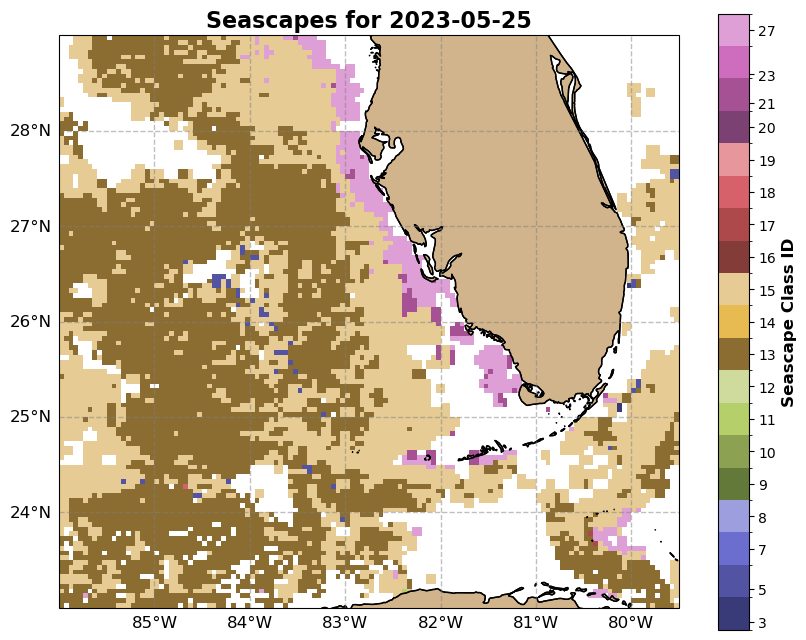

In [6]:
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm

#  Map Seascape Data for a Single Time Step as a test

# Select the Data for a Single Time Step 
seascape_selected = ds.isel(time=31)

# Find every unique class across the ENTIRE dataset to ensure absolute consistency
all_values = ds['CLASS'].values
global_classes = np.unique(all_values[~np.isnan(all_values)]).astype(int)
num_global_classes = len(global_classes)

# Select a base color palette. If you have more than 20 classes, we stitch 
# tab20b and tab20c together so colors never repeat.
if num_global_classes <= 20:
    colors = plt.get_cmap('tab20b')(np.linspace(0, 1, num_global_classes))
else:
    combined_palette = np.vstack([
        plt.get_cmap('tab20b')(np.linspace(0, 1, 20)),
        plt.get_cmap('tab20c')(np.linspace(0, 1, 20))
    ])
    colors = combined_palette[:num_global_classes]

# Create the global, unchanging colormap and normalization bounds
common_cmap = ListedColormap(colors)
common_bounds = np.append(global_classes, global_classes[-1] + 1) - 0.5
common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)

# --- Set Up the Map ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

# --- Plot the Seascape Data ---
# Pass the normalization object ('norm') to ensure correct color mapping
mesh = ax.pcolormesh(
    seascape_selected['lon'], 
    seascape_selected['lat'], 
    seascape_selected['CLASS'],
    cmap=common_cmap,
    norm=common_norm, # Apply the normalization rule
    transform=ccrs.PlateCarree()
)

# --- Add Map Features ---
ax.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='tan')
ax.add_feature(cfeature.COASTLINE)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# --- Add Colorbar and Title ---
# The colorbar will automatically use the correct normalization from 'mesh'
cbar = plt.colorbar(mesh, ax=ax, ticks=unique_classes)
cbar.set_label('Seascape Class ID', fontsize=12, weight='bold')

# Get the date from the selected data
seascape_date = pd.to_datetime(seascape_selected.time.values).strftime('%Y-%m-%d')

# Set the title using the extracted date
ax.set_title(f'Seascapes for {seascape_date}', fontsize=16, weight='bold')

plt.show()

In [7]:
# First, let's define the parameters and prepare the data structures needed for the analysis.

# --- Parameters ---
N_PIXELS = 3  # Radius in pixels to search around each station
PIX_RESOLUTION_DEG = 0.0416 # Approximate resolution of 4-km seascapes in degrees
SEARCH_RADIUS_DEG = N_PIXELS * PIX_RESOLUTION_DEG

# Prepare the seascape grid coordinates for efficient searching
# Flatten the lat/lon grid into a list of (lat, lon) points
lon_grid, lat_grid = np.meshgrid(ds['lon'].values, ds['lat'].values)
grid_points = np.vstack([lat_grid.ravel(), lon_grid.ravel()]).T

# Create a KD-Tree for fast nearest-neighbor searches. This is much faster
# than calculating the distance to every single grid point.
kdtree = KDTree(grid_points)

### USE THE NEXT CELL FOR MONTHLY SEASCAPE EXTRACTIONS

In [ ]:
    # --- 1. Prepare FRESCA DataFrame ---
# Ensure datetime_utc is in datetime format and create year/month/day columns for the loop
fresca_df['datetime_utc'] = pd.to_datetime(fresca_df['datetime_utc'], errors='coerce')
fresca_df['year'] = fresca_df['datetime_utc'].dt.year
fresca_df['month'] = fresca_df['datetime_utc'].dt.month
fresca_df['day'] = fresca_df['datetime_utc'].dt.day
fresca_df.dropna(subset=['year', 'month', 'day'], inplace=True) # Drop rows where date conversion failed

# Convert year/month/day to integers to ensure the filter works correctly
fresca_df[['year', 'month', 'day']] = fresca_df[['year', 'month', 'day']].astype(int)

# --- 2. Main Loop for Monthly Analysis ---
# List to store the final results
all_sites_summary_monthly = []

# Loop through each time step (month) in the seascape data
for i, t_row in TIMEVEC.iterrows():
    current_year = t_row['year']
    current_month = t_row['month']

    # --- Find corresponding data for this month ---
    # MODIFIED: Changed sfer_df to fresca_df and removed the 'station_type' filter
    monthly_df = fresca_df[
        (fresca_df['year'] == current_year) &
        (fresca_df['month'] == current_month)
    ].copy()

    # Drop rows where 'lat' or 'lon' are missing to prevent the ValueError
    monthly_df.dropna(subset=['lat', 'lon'], inplace=True)

    if monthly_df.empty:
        print(f"No FRESCA data for {current_year}-{current_month:02d}. Skipping.")
        continue

    print(f"Processing {len(monthly_df)} samples for {current_year}-{current_month:02d}...")

    seascape_monthly = ds.isel(time=i)
    
    # --- B. Extract Surrounding Seascape Pixels ---
    # MODIFIED: Changed column names to 'lat' and 'lon'
    station_points = monthly_df[['lat', 'lon']].values
    nearby_indices_list = kdtree.query_ball_point(station_points, r=SEARCH_RADIUS_DEG)
    monthly_df['nearby_grid_indices'] = nearby_indices_list
    
    # --- C. Calculate Modal Seascape Class ---
    site_summaries = []
    for idx, station in monthly_df.iterrows():
        flat_indices = station['nearby_grid_indices']
        
        if not flat_indices:
            modal_class, mean_prob_of_modal = np.nan, np.nan
        else:
            rows, cols = np.unravel_index(flat_indices, seascape_monthly['CLASS'].shape)
            nearby_classes = seascape_monthly['CLASS'].values[rows, cols]
            nearby_probs = seascape_monthly['P'].values[rows, cols]
            
            valid_mask = ~np.isnan(nearby_classes)
            valid_classes = nearby_classes[valid_mask]
            
            if valid_classes.size > 0:
                modal_class = sp_mode(valid_classes, keepdims=False).mode
                valid_probs = nearby_probs[valid_mask]
                probs_of_modal_class = valid_probs[valid_classes == modal_class]
                mean_prob_of_modal = np.mean(probs_of_modal_class)
            else:
                modal_class, mean_prob_of_modal = np.nan, np.nan

        # MODIFIED: Dictionary updated with columns from fresca_df
        site_summaries.append({
            'ifcb_filename': station['ifcb_filename'],
            'year': station['year'],
            'month': station['month'],
            'day': station['day'],
            'datetime_utc': station['datetime_utc'],
            'lat': station['lat'],
            'lon': station['lon'],
            'sample_vol': station['sample_vol'],
            'k_brevis_total': station['k_brevis_total'],
            'modal_seascape_class': modal_class,
            'mean_seascape_prob': mean_prob_of_modal
        })

    all_sites_summary_monthly.extend(site_summaries)

# Convert the final list of results into a pandas DataFrame
conc_class_per_site_monthly = pd.DataFrame(all_sites_summary_monthly)

# Define the output filename
output_filename = "seascape_fresca_summary_monthly.tsv"

# Save the DataFrame to a .tsv file
conc_class_per_site_monthly.to_csv(output_filename, sep='\t', index=False)

print("\n--- Analysis Complete ---")
print("Final summary of modal seascape classes for FRESCA data:")
print(conc_class_per_site_monthly.head())
print(f"\nResults saved to '{output_filename}'")

### USE THE NEXT CELL FOR 8-DAY SEASCAPE EXTRACTIONS

In [8]:
# --- 1. Prepare FRESCA DataFrame ---
# Ensure datetime_utc is in datetime format for date-range comparisons
fresca_df['datetime_utc'] = pd.to_datetime(fresca_df['datetime_utc'], errors='coerce')

# Create 'year', 'month', and 'day' columns from 'datetime_utc'
# These are needed for the final output dictionary.
fresca_df['year'] = fresca_df['datetime_utc'].dt.year
fresca_df['month'] = fresca_df['datetime_utc'].dt.month
fresca_df['day'] = fresca_df['datetime_utc'].dt.day

# =========================================================================
# LOCK COLORSCALE GLOBALLY (BEFORE THE LOOP)
# =========================================================================
# Find every unique class across the ENTIRE dataset 
all_values = ds['CLASS'].values
global_classes = np.unique(all_values[~np.isnan(all_values)]).astype(int)
num_global_classes = len(global_classes)

# 2. Build a stable palette (combining tab20b and tab20c if classes exceed 20)
if num_global_classes <= 20:
    colors = plt.get_cmap('tab20b')(np.linspace(0, 1, num_global_classes))
else:
    combined_palette = np.vstack([
        plt.get_cmap('tab20b')(np.linspace(0, 1, 20)),
        plt.get_cmap('tab20c')(np.linspace(0, 1, 20))
    ])
    colors = combined_palette[:num_global_classes]

# 3. Create the fixed global colormap and normalization boundaries
common_cmap = ListedColormap(colors)
common_bounds = np.append(global_classes, global_classes[-1] + 1) - 0.5
common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)
# =========================================================================

# --- 2. Main Loop for 8-Day Analysis ---
all_sites_summary_8day = []

# Loop through each 8-day time window
for i in range(len(ds.time) - 1):
    start_date = ds.time.values[i]
    end_date = ds.time.values[i+1]

    # --- Find corresponding data within the 8-day window ---
    # MODIFIED: Changed to fresca_df and removed the 'station_type' filter
    data_in_window_df = fresca_df[
        (fresca_df['datetime_utc'] >= start_date) & 
        (fresca_df['datetime_utc'] < end_date)
    ].copy()

    # Drop rows where 'lat' or 'lon' are missing to prevent errors
    data_in_window_df.dropna(subset=['lat', 'lon'], inplace=True)

    if data_in_window_df.empty:
        print(f"No valid FRESCA data for window starting {pd.to_datetime(start_date).strftime('%Y-%m-%d')}. Skipping.")
        continue

    print(f"Processing {len(data_in_window_df)} samples for window starting {pd.to_datetime(start_date).strftime('%Y-%m-%d')}...")

    seascape_8day = ds.isel(time=i)

    # --- A. Create the Map ---
    if not data_in_window_df.empty:
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
        ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())
        
        # Get unique classes just for this specific slice's colorbar ticks
        class_values = seascape_8day['CLASS'].values
        unique_classes = np.unique(class_values[~np.isnan(class_values)]).astype(int)

        if unique_classes.size > 0:
            # FIXED: Always use common_cmap and common_norm so colors never shift
            mesh = ax.pcolormesh(
                seascape_8day['lon'], seascape_8day['lat'], seascape_8day['CLASS'], 
                cmap=common_cmap, norm=common_norm, transform=ccrs.PlateCarree()
            )
            # Only show ticks for classes present in this frame, perfectly positioned by the global norm
            cbar = plt.colorbar(mesh, ax=ax, ticks=unique_classes, pad=0.05, aspect=25)
            cbar.set_label('Seascape Class ID', fontsize=12)

        ax.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='tan')
        ax.add_feature(cfeature.COASTLINE)
        ax.gridlines(draw_labels=True, linestyle='--')

        # Filter the FRESCA DataFrame for high K. brevis concentrations
        high_k_brevis_df = data_in_window_df[data_in_window_df['k_brevis_total'] >= 5000]

        # Plot filtered FRESCA stations
        if not high_k_brevis_df.empty:
            ax.scatter(
                high_k_brevis_df['lon'], 
                high_k_brevis_df['lat'], 
                s=80,                  
                c='red',               
                marker='*', 
                edgecolors='black',    
                transform=ccrs.PlateCarree(), 
                label='K. brevis >= 5000 cells/L',
                zorder=10              
            )
            ax.legend()

        # Parse string ranges and save figures
        start_date_str = pd.to_datetime(start_date).strftime('%Y-%m-%d')
        end_date_str = pd.to_datetime(end_date).strftime('%Y-%m-%d')
        
        ax.set_title(f"Seascapes: {start_date_str}_to_{end_date_str}", fontsize=16)
        plt.savefig(f"{start_date_str}_to_{end_date_str}_map.png", dpi=150, bbox_inches='tight')
        plt.close(fig)
        
    # --- B. Extract Surrounding Seascape Pixels ---
    # Changed column names to 'lat' and 'lon'
    station_points = data_in_window_df[['lat', 'lon']].values
    nearby_indices_list = kdtree.query_ball_point(station_points, r=SEARCH_RADIUS_DEG)
    data_in_window_df['nearby_grid_indices'] = nearby_indices_list
        
    # --- C. Calculate Modal Seascape Class ---
    site_summaries = []
    for idx, station in data_in_window_df.iterrows():
        flat_indices = station['nearby_grid_indices']
        
        if not flat_indices:
            modal_class, mean_prob_of_modal = np.nan, np.nan
        else:
            rows, cols = np.unravel_index(flat_indices, seascape_8day['CLASS'].shape)
            nearby_classes = seascape_8day['CLASS'].values[rows, cols]
            nearby_probs = seascape_8day['P'].values[rows, cols]
            
            valid_mask = ~np.isnan(nearby_classes)
            valid_classes = nearby_classes[valid_mask]
            
            if valid_classes.size > 0:
                modal_class = sp_mode(valid_classes, keepdims=False).mode
                valid_probs = nearby_probs[valid_mask]
                probs_of_modal_class = valid_probs[valid_classes == modal_class]
                mean_prob_of_modal = np.mean(probs_of_modal_class)
            else:
                modal_class, mean_prob_of_modal = np.nan, np.nan

        # Dictionary updated with columns from fresca_df
        site_summaries.append({
            'ifcb_filename': station['ifcb_filename'],
            'year': station['year'],
            'month': station['month'],
            'day': station['day'],
            'datetime_utc': station['datetime_utc'],
            'lat': station['lat'],
            'lon': station['lon'],
            'sample_vol': station['sample_vol'],
            'k_brevis_total': station['k_brevis_total'],
            'modal_seascape_class': modal_class,
            'mean_seascape_prob': mean_prob_of_modal
        })
    all_sites_summary_8day.extend(site_summaries)

# Convert the final list of results into a pandas DataFrame
conc_class_per_site_8day = pd.DataFrame(all_sites_summary_8day)

# Define the output filename
output_filename = "seascape_fresca_summary_8day.tsv"

# Save the DataFrame to a .tsv file
conc_class_per_site_8day.to_csv(output_filename, sep='\t', index=False)

print("\n--- 8-Day Analysis Complete ---")
print("Final summary of modal seascape classes for FRESCA data:")
print(conc_class_per_site_8day.head())
print(f"\nResults saved to '{output_filename}'")

No valid FRESCA data for window starting 2022-09-22. Skipping.
No valid FRESCA data for window starting 2022-09-30. Skipping.
Processing 378 samples for window starting 2022-10-08...
No valid FRESCA data for window starting 2022-10-16. Skipping.
No valid FRESCA data for window starting 2022-10-24. Skipping.
No valid FRESCA data for window starting 2022-11-01. Skipping.
No valid FRESCA data for window starting 2022-11-09. Skipping.
No valid FRESCA data for window starting 2022-11-17. Skipping.
No valid FRESCA data for window starting 2022-11-25. Skipping.
Processing 376 samples for window starting 2022-12-03...
No valid FRESCA data for window starting 2022-12-11. Skipping.
No valid FRESCA data for window starting 2022-12-19. Skipping.
No valid FRESCA data for window starting 2022-12-27. Skipping.
No valid FRESCA data for window starting 2023-01-01. Skipping.
Processing 388 samples for window starting 2023-01-09...
Processing 20 samples for window starting 2023-01-17...
No valid FRESCA d

## Merge monthly and 8-day seascape tables into a single file. Monthly and 8-day cells must be run prior to this merge

In [ ]:
# maximum of k_brevis_total in conc_class_per_site_8day
max_k_brevis = conc_class_per_site_8day['k_brevis_total'].max()
mean_k_brevis = conc_class_per_site_8day['k_brevis_total'].mean()

print(f"Maximum K. brevis total in 8-day data: {max_k_brevis}")
print(f"Mean K. brevis total in 8-day data: {mean_k_brevis}")

# Create a histogram for k_brevis_total
plt.figure(figsize=(10, 6))
plt.hist(conc_class_per_site_8day['k_brevis_total'][conc_class_per_site_8day['k_brevis_total'] > 100000], 
         bins=30, color='blue', edgecolor='black', alpha=0.7)
plt.title('Histogram of K. brevis Total (8-day Data, Excluding Zeros)', fontsize=14)
plt.xlabel('K. brevis Total (cells/L)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
# Start with the 8-day data as the base
merged_df = conc_class_per_site_8day.copy()

# Directly append the two columns from the monthly data
# This assumes both tables have the exact same row order
merged_df['modal_class_monthly'] = conc_class_per_site_monthly['modal_seascape_class']
merged_df['mean_prob_monthly'] = conc_class_per_site_monthly['mean_seascape_prob']

# remane the columns for 8-day seascapes
merged_df.rename(columns={'modal_seascape_class': 'modal_class_8day'}, inplace=True)  
merged_df.rename(columns={'mean_seascape_prob': 'mean_prob_8day'}, inplace=True)

# --- Save the Final Merged File ---
output_filename = "seascape_fresca_summary_appended.tsv"
merged_df.to_csv(output_filename, sep='\t', index=False)

print("\n--- Appending Complete ---")
print("Final appended summary:")
print(merged_df.head())
print(f"\nResults saved to '{output_filename}'")

Total records found with K. brevis >= 1,000 cells/L: 657


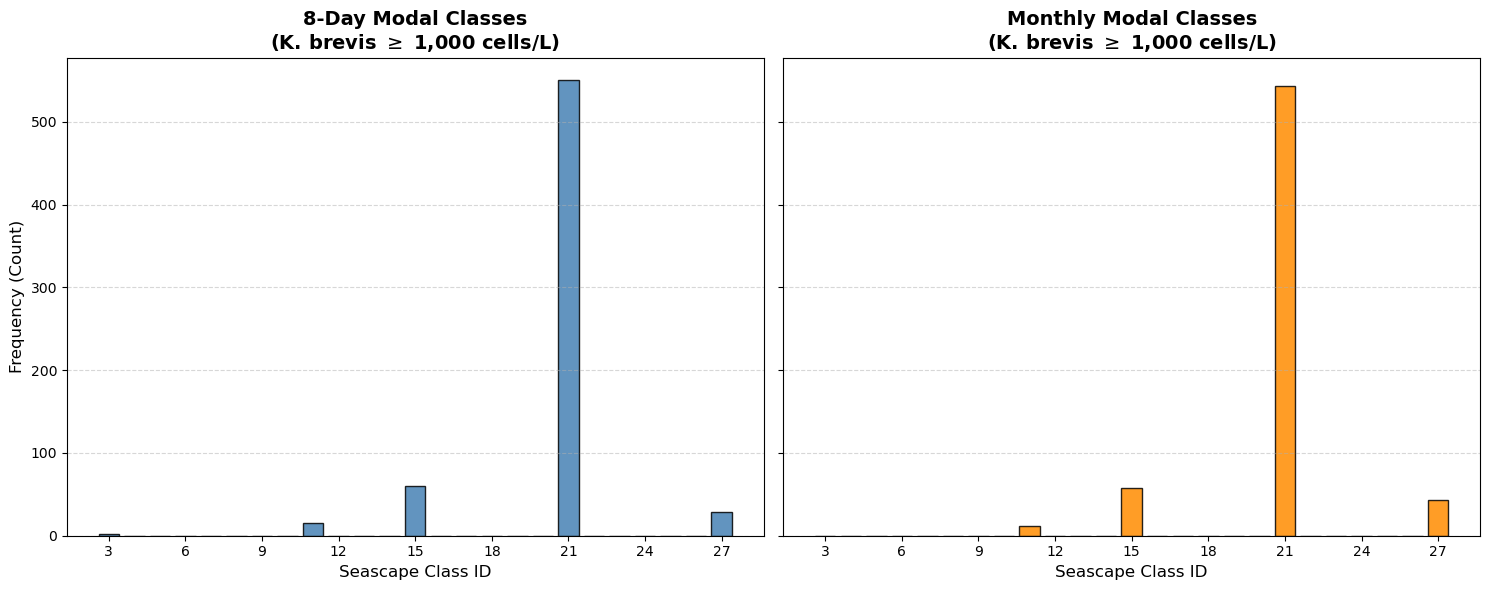

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Load the Data ---
df = pd.read_csv('seascape_fresca_summary_appended.tsv', sep='\t')

# --- 2. Filter for K. brevis >= 1,000 cells/L ---
# This creates a subset containing only the rows meeting your criteria
df_filtered = df[df['k_brevis_total'] >= 1000].copy()

print(f"Total records found with K. brevis >= 1,000 cells/L: {len(df_filtered)}")

# --- 3. Define Discrete Bins Based on Filtered Data ---
# Binning using the filtered dataset ensures the X-axis limits fit your data range beautifully
all_classes = pd.concat([df_filtered['modal_class_8day'], df_filtered['modal_class_monthly']]).dropna()
if not all_classes.empty:
    min_class = int(all_classes.min())
    max_class = int(all_classes.max())
    bins = np.arange(min_class - 0.5, max_class + 1.5, 1)
else:
    bins = 'auto'

# --- 4. Set up the Figure Structure ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Plot 1: 8-Day Modal Class Histogram (Filtered Data)
axes[0].hist(
    df_filtered['modal_class_8day'].dropna(), 
    bins=bins, 
    rwidth=0.8, 
    color='steelblue', 
    edgecolor='black', 
    alpha=0.85
)
axes[0].set_title('8-Day Modal Classes\n(K. brevis $\geq$ 1,000 cells/L)', fontsize=14, weight='bold')
axes[0].set_xlabel('Seascape Class ID', fontsize=12)
axes[0].set_ylabel('Frequency (Count)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Monthly Modal Class Histogram (Filtered Data)
axes[1].hist(
    df_filtered['modal_class_monthly'].dropna(), 
    bins=bins, 
    rwidth=0.8, 
    color='darkorange', 
    edgecolor='black', 
    alpha=0.85
)
axes[1].set_title('Monthly Modal Classes\n(K. brevis $\geq$ 1,000 cells/L)', fontsize=14, weight='bold')
axes[1].set_xlabel('Seascape Class ID', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Optimize spacing and force integer ticks on the X-axis
for ax in axes:
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()